# RA-Trabecular — Notebook 01: First Reproducible Example

**Version:** 0.1.1  
**Author:** Verónica Zumpano Blumenfeld  
**ORCID:** 0009-0006-2030-1849  
**License:** Apache 2.0

This notebook demonstrates the complete RA-Trabecular workflow:

1. Generate a Voronoi-based trabecular network.
2. Apply progressive erosion under three regimes.
3. Compute IRCE trajectories (additive and multiplicative).
4. Identify the predicted critical transition.
5. Visualize the results (writes `../figures/01_irce_trajectory.png`).

## The IRCE

$$\mathrm{IRCE} = \alpha M + \beta T + \gamma A, \qquad \alpha+\beta+\gamma = 1$$

$$\mathrm{IRCE}_{\mathrm{mult}} = M^{\alpha}\, T^{\beta}\, A^{\gamma}$$

where $M = E^*_{\mathrm{eroded}}/E^*_{\mathrm{healthy}}$ is the effective modulus ratio, $T = N_{\mathrm{LCC}}/N_{\mathrm{total}}$ the connectivity of the load-bearing subnetwork, and $A$ the fraction of healthy fabric retained along the principal load axis. All three equal 1 for the healthy network, so $\mathrm{IRCE} = 1$ at the start of every trajectory. See `docs/irce_definition.md` for the formal definition.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from ra_trabecular import (
    generate_voronoi_network, progressive_erosion, ErosionRegime,
    compute_irce, compute_irce_multiplicative,
)
from ra_trabecular.connectivity import percolation_order_parameter

RNG_SEED = 42
N_SEEDS = 200
DOMAIN_SIZE = 10.0
N_STEPS = 33               # p_removed = 0, 0.025, ..., 0.8
MAX_REMOVAL = 0.8
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

## 2. Generate the healthy reference network

In [2]:
healthy = generate_voronoi_network(
    n_seeds=N_SEEDS, domain_size=DOMAIN_SIZE, rng_seed=RNG_SEED
)
print(f"nodes in graph: {healthy.graph.number_of_nodes()}")
print(f"struts (edges): {healthy.n_edges}")
print(f"mean coordination z: {healthy.mean_coordination:.2f}")

ref = compute_irce(healthy, healthy)
print(f"IRCE(healthy) = {ref.irce:.3f}  (M={ref.modulus_ratio}, T={ref.connectivity_ratio}, A={ref.anisotropy})")
assert abs(ref.irce - 1.0) < 1e-9

nodes in graph: 917
struts (edges): 1724
mean coordination z: 3.76
IRCE(healthy) = 1.000  (M=1.0, T=1.0, A=1.0)


## 3. Erosion trajectories and IRCE

In [3]:
results = {}
for regime in ErosionRegime:
    trajectory = progressive_erosion(
        healthy, n_steps=N_STEPS, max_removal_fraction=MAX_REMOVAL,
        regime=regime, rng_seed=RNG_SEED,
    )
    add = [compute_irce(s.network, healthy) for s in trajectory]
    mult = [compute_irce_multiplicative(s.network, healthy) for s in trajectory]
    results[regime.value] = {
        "p": np.array([s.p_removed for s in trajectory]),
        "irce": np.array([r.irce for r in add]),
        "irce_mult": np.array([r.irce for r in mult]),
        "M": np.array([r.modulus_ratio for r in add]),
        "T": np.array([r.connectivity_ratio for r in add]),
        "A": np.array([r.anisotropy for r in add]),
        "P_inf": np.array([
            percolation_order_parameter(s.network, healthy.graph.number_of_nodes())
            for s in trajectory
        ]),
    }

## 4. Critical transition

As a first, simple estimator, the critical erosion fraction $p_c$ is taken at the steepest drop of the IRCE (largest $-\Delta\mathrm{IRCE}/\Delta p$), and $\mathrm{IRCE}_c$ is the IRCE just before that drop. Finite-size scaling across many realizations is planned for v0.2.0.

In [4]:
print(f"{'regime':<14}{'p_c':>8}{'IRCE_c':>10}{'max drop':>10}")
for name, r in results.items():
    drops = -np.diff(r["irce"])
    i = int(np.argmax(drops))
    r["p_c"], r["irce_c"] = r["p"][i], r["irce"][i]
    print(f"{name:<14}{r['p_c']:>8.3f}{r['irce_c']:>10.3f}{drops[i]:>10.3f}")

regime             p_c    IRCE_c  max drop
uniform          0.500     0.281     0.158
peripheral       0.050     0.918     0.045
osteoclastic     0.325     0.574     0.082


## 5. Figure

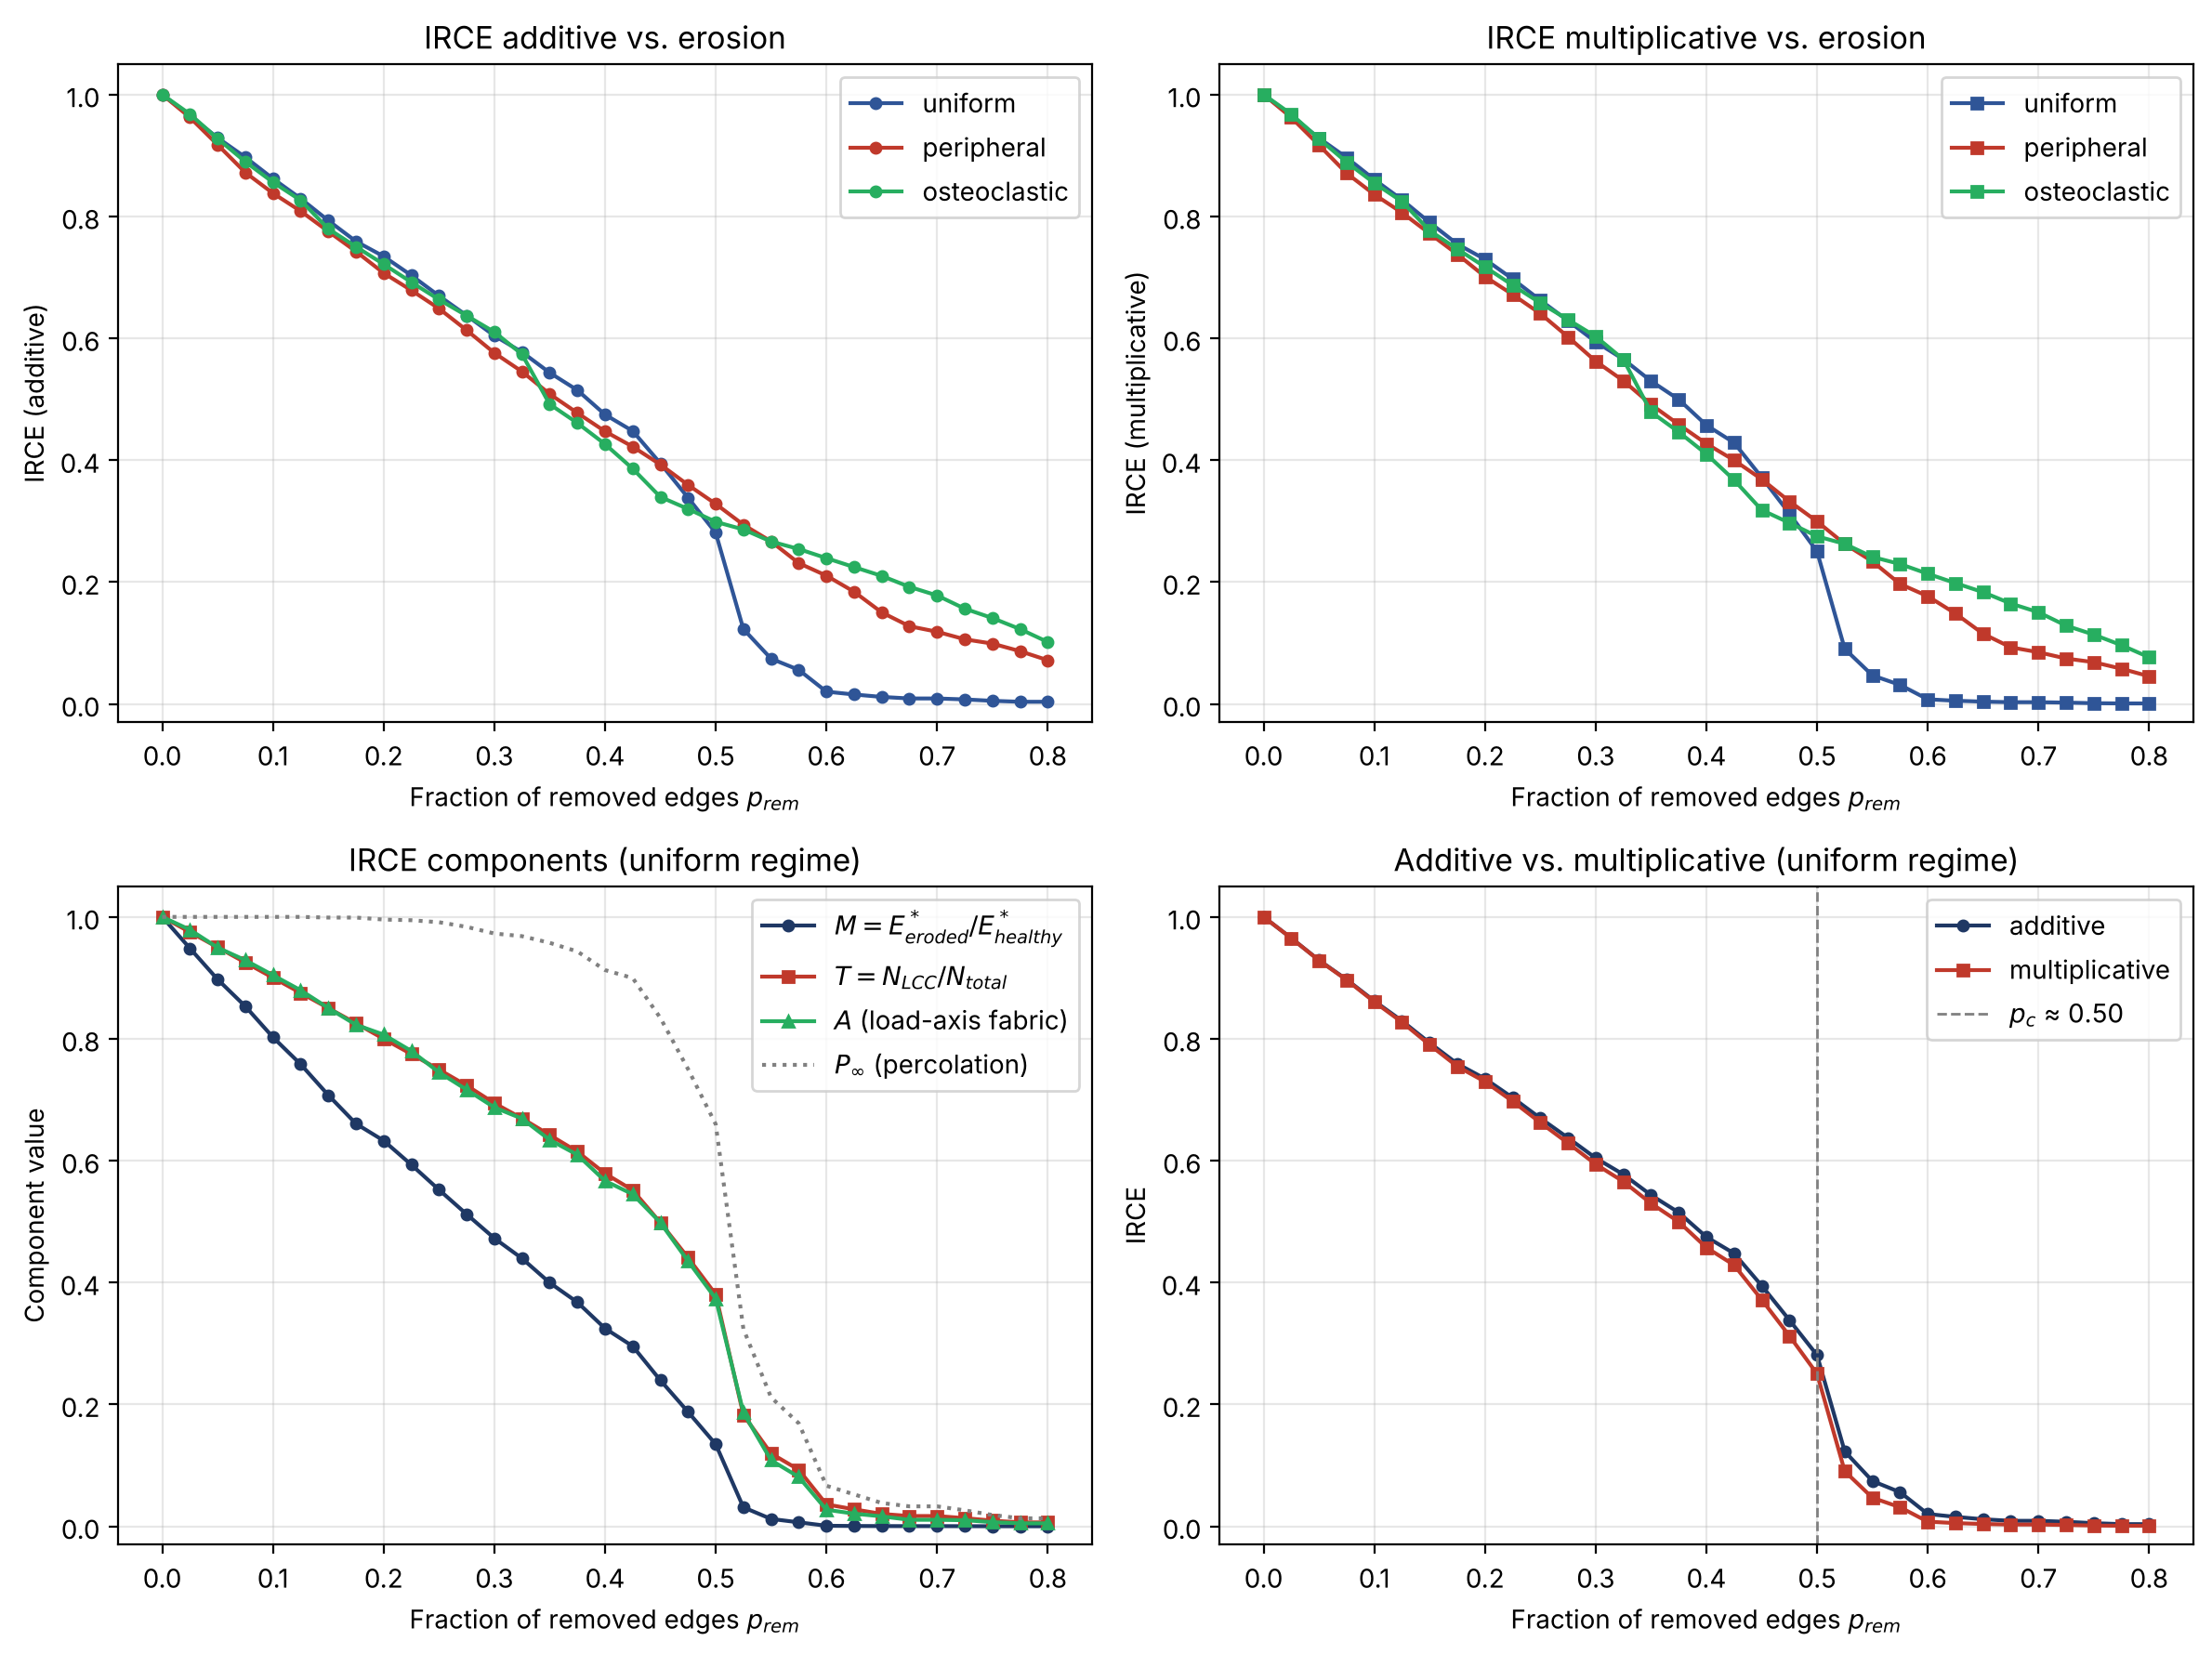

In [5]:
colors = {"uniform": "#2f5597", "peripheral": "#c0392b", "osteoclastic": "#27ae60"}
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

ax = axes[0, 0]
for name, r in results.items():
    ax.plot(r["p"], r["irce"], "o-", ms=4, color=colors[name], label=name)
ax.set(title="IRCE additive vs. erosion", ylabel="IRCE (additive)")

ax = axes[0, 1]
for name, r in results.items():
    ax.plot(r["p"], r["irce_mult"], "s-", ms=4, color=colors[name], label=name)
ax.set(title="IRCE multiplicative vs. erosion", ylabel="IRCE (multiplicative)")

u = results["uniform"]
ax = axes[1, 0]
ax.plot(u["p"], u["M"], "o-", ms=4, color="#1f3864", label=r"$M = E^*_{eroded}/E^*_{healthy}$")
ax.plot(u["p"], u["T"], "s-", ms=4, color="#c0392b", label=r"$T = N_{LCC}/N_{total}$")
ax.plot(u["p"], u["A"], "^-", ms=4, color="#27ae60", label=r"$A$ (load-axis fabric)")
ax.plot(u["p"], u["P_inf"], ":", color="gray", label=r"$P_\infty$ (percolation)")
ax.set(title="IRCE components (uniform regime)", ylabel="Component value")

ax = axes[1, 1]
ax.plot(u["p"], u["irce"], "o-", ms=4, color="#1f3864", label="additive")
ax.plot(u["p"], u["irce_mult"], "s-", ms=4, color="#c0392b", label="multiplicative")
ax.axvline(u["p_c"], ls="--", color="gray", lw=1, label=f"$p_c$ ≈ {u['p_c']:.2f}")
ax.set(title="Additive vs. multiplicative (uniform regime)", ylabel="IRCE")

for ax in axes.flat:
    ax.set_xlabel(r"Fraction of removed edges $p_{rem}$")
    ax.set_ylim(-0.03, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
fig.savefig(FIG_DIR / "01_irce_trajectory.png", dpi=150)
plt.show()

## 6. Observations

* Every trajectory starts at $\mathrm{IRCE} = 1$ and is non-increasing.
* Under **uniform** erosion the IRCE drops abruptly near $p \approx 0.5$, where the load-bearing cluster breaks up ($P_\infty$ collapses): the percolation transition the framework targets.
* Spatially correlated regimes (**peripheral**, **osteoclastic**) degrade more gradually: erosion concentrated in one region leaves the rest of the network connected for longer. Because they show no single abrupt drop, the steepest-drop estimate of $p_c$ in Section 4 is not meaningful for them; it is only reliable for the uniform regime here.
* Under spatially isotropic erosion $A$ closely tracks $T$; the anisotropy term becomes informative with direction-selective erosion (planned for v0.2.0).